# Papaya2 vs. `pykarambola`: 2D Irreducible Minkowski Tensor Validation

Live head-to-head numerical accuracy, orientation-robustness, and runtime-scaling
validation of **`pykarambola.imt2d`** (pure NumPy) against the upstream C++
reference library [**`morphometry/papaya2`**](https://github.com/morphometry/papaya2)
(`papaya2.hpp`, compiled with `g++ -O3`).

### Validation Scope

| Section | Benchmark / Test Suite | Quantities & Checks |
|---|---|---|
| **1** | **Analytic & Random Polygons** (concave 5-gon, equilateral triangle, 3:8 ellipse, random 37-gon) | `area`, `perimeter`, `beta102`, `isoper`, $q_2\text{--}q_{12}$, $\psi_2\text{--}\psi_{12}$ |
| **2** | **Exhaustive 16 Marching-Squares Neighborhoods × 8 Flag Combos** (128 runs, $\Delta x = 1.7, \Delta y = 2.3$) | Every 4-pixel LUT case × `{interpolated, regular}` × `{white, black}` × `connect {white, black}` |
| **3** | **`potato.png` Golden Grayscale Image, Minkowski Map & 25-Threshold Sweep** | Golden reference table (`xy_order=True` & default `(row, col)`), $\psi_2$ map, 25-level excursion-set curve + residuals |
| **4** | **Comprehensive Error Diagnostics** (64×48 random grayscale × 24 mode/flag combos + 15 Minkowski maps) | Validation scatter ($y = x$), log-scale error bar chart, suite × feature relative-error heatmap, summary table |
| **5** | **Rotated Ellipses (Orientation Robustness, $0^\circ\text{--}90^\circ$)** | Interpolated vs. regular marching squares against analytic 8:3 ellipse + Python-vs-C++ residuals |
| **6** | **Runtime Scaling ($128^2\text{--}2048^2$)** | Pure NumPy `pykarambola.imt_image` vs. C++ `papaya2 -O3` on smooth GRF and worst-case white noise |


In [1]:
import atexit
import json
import os
import platform
import shutil
import subprocess
import sys
import tempfile
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from PIL import Image
from scipy.ndimage import gaussian_filter

import pykarambola as pk
from pykarambola import imt_image, imt_polygon, minkowski_map

# ── Publication-style matplotlib defaults ────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
})

# ── Locate morphometry/papaya2 checkout ──────────────────────────────────────
PAPAYA2_DIR = os.environ.get("PAPAYA2_DIR", "/tmp/papaya2")
if not os.path.isfile(os.path.join(PAPAYA2_DIR, "include", "papaya2.hpp")):
    raise FileNotFoundError(
        f"Could not find papaya2.hpp under PAPAYA2_DIR={PAPAYA2_DIR!r}.\n"
        "Clone morphometry/papaya2 and set PAPAYA2_DIR, e.g.:\n"
        "  git clone https://github.com/morphometry/papaya2 /tmp/papaya2\n"
        "  export PAPAYA2_DIR=/tmp/papaya2"
    )

gxx_ver = subprocess.check_output(["g++", "--version"], text=True).splitlines()[0]
try:
    papaya2_sha = subprocess.check_output(
        ["git", "-C", PAPAYA2_DIR, "rev-parse", "HEAD"], text=True
    ).strip()
except Exception:
    papaya2_sha = "unknown (not a git checkout)"

print("Environment")
print("-" * 64)
print(f"Python      : {platform.python_version()} ({platform.platform()})")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"pykarambola : {pk.__version__}")
print(f"g++         : {gxx_ver}")
print(f"papaya2     : {PAPAYA2_DIR} @ {papaya2_sha}")


Environment
----------------------------------------------------------------
Python      : 3.11.2 (Linux-6.12.105+-x86_64-with-glibc2.36)
NumPy       : 2.4.6
SciPy       : 1.17.1
Pandas      : 3.1.1
Matplotlib  : 3.11.2
pykarambola : 0.7.0
g++         : g++ (Debian 12.2.0-14+deb12u1) 12.2.0
papaya2     : /tmp/papaya2 @ 5d79180825fe7c797bfcadbb67e0860f8cee5a9d


## Configuration & C++ `papaya2` Oracle Helper

To re-run this notebook against a live C++ reference on any machine with `g++`
installed:

```bash
git clone https://github.com/morphometry/papaya2 /tmp/papaya2
export PAPAYA2_DIR=/tmp/papaya2   # optional if cloned into /tmp/papaya2
```

The cell below compiles a self-contained C++17 oracle driver against
`papaya2.hpp` and `papaya2/pingfile.hpp` into an automatically cleaned
temporary directory (`g++ -O3 -std=c++17`), leaving the repository completely
clean. No external C++ libraries beyond the standard library are required.


In [2]:
ORACLE_CPP_SRC = r'''
#include <papaya2.hpp>
#include <papaya2/pingfile.hpp>
#include <chrono>
#include <cmath>
#include <cstdio>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <string>
#include <vector>

using namespace papaya2;

static void print_acc_json(const MinkowskiAccumulator &acc) {
    std::cout << std::setprecision(17);
    std::cout << "{\"area\":" << acc.area()
              << ",\"perimeter\":" << acc.perimeter()
              << ",\"beta102\":";
    double b = acc.beta102();
    if (!std::isfinite(b)) std::cout << "null"; else std::cout << b;
    std::cout << ",\"isoper\":";
    double iso = acc.isoper();
    if (!std::isfinite(iso)) std::cout << "null"; else std::cout << iso;
    std::cout << ",\"psi_re\":[";
    for (int s = 2; s <= 12; ++s) {
        if (s > 2) std::cout << ",";
        std::cout << acc.imt(s).real();
    }
    std::cout << "],\"psi_im\":[";
    for (int s = 2; s <= 12; ++s) {
        if (s > 2) std::cout << ",";
        std::cout << acc.imt(s).imag();
    }
    std::cout << "],\"q\":[";
    for (int s = 2; s <= 12; ++s) {
        if (s > 2) std::cout << ",";
        double qv = acc.msm(s);
        if (std::isnan(qv)) std::cout << "null"; else std::cout << qv;
    }
    std::cout << "]}\n";
}

// Read binary raw float64 image of shape (W, H) in C-order: buf[i*H + j] -> ph(i, j)
static Photo read_photo_bin(const std::string &path, int W, int H, double dx, double dy) {
    Photo ph;
    ph.set_coordinates(0.0, 0.0, W * dx, H * dy, W, H);
    std::ifstream ifs(path, std::ios::binary);
    std::vector<double> buf(size_t(W) * size_t(H));
    ifs.read(reinterpret_cast<char *>(buf.data()), sizeof(double) * buf.size());
    for (int i = 0; i < W; ++i)
        for (int j = 0; j < H; ++j)
            ph(i, j) = buf[size_t(i) * size_t(H) + size_t(j)];
    return ph;
}

int main(int argc, char **argv) {
    if (argc < 2) return 1;
    std::string cmd = argv[1];

    if (cmd == "potato") {
        PingFile pf(argv[2]);
        double thr = std::stod(argv[3]);
        print_acc_json(imt_interpolated_marching_squares(pf, thr));
        return 0;
    }

    if (cmd == "polygon") {
        // Read binary float64 vertices of shape (N, 2) from file
        int n = std::stoi(argv[2]);
        std::ifstream ifs(argv[3], std::ios::binary);
        std::vector<double> buf(size_t(n) * 2);
        ifs.read(reinterpret_cast<char *>(buf.data()), sizeof(double) * buf.size());
        std::vector<vec_t> verts;
        verts.reserve(n);
        for (int i = 0; i < n; ++i)
            verts.push_back({buf[2 * i], buf[2 * i + 1]});
        print_acc_json(imt_polygon(verts));
        return 0;
    }

    if (cmd == "image") {
        std::string path = argv[2];
        int W = std::stoi(argv[3]);
        int H = std::stoi(argv[4]);
        double dx = std::stod(argv[5]);
        double dy = std::stod(argv[6]);
        double thr = std::stod(argv[7]);
        std::string bmode = argv[8];
        double pad_val = std::stod(argv[9]);
        std::string method = argv[10];
        std::string analyze = argv[11];
        std::string connect = argv[12];

        Photo ph = read_photo_bin(path, W, H, dx, dy);
        MarchingSquaresFlags flags;
        if (analyze == "b") flags |= ANALYZE_BLACK;
        if (connect == "b") flags |= CONNECT_BLACK;

        auto run_on = [&](const auto &view) {
            return (method == "reg")
                ? imt_regular_marching_squares(view, thr, flags)
                : imt_interpolated_marching_squares(view, thr, flags);
        };

        if (bmode == "none") {
            print_acc_json(run_on(ph));
        } else if (bmode == "const") {
            print_acc_json(run_on(make_padded_view(ph, pad_val)));
        } else {
            // Unique W*H periodic neighborhoods (matches pypaya2.cpp)
            auto padded = make_periodic_view(ph);
            MinkowskiAccumulator acc;
            vec_t pix_diag = pixel_diagonal(padded);
            vec_t origin = padded.origin();
            if (method == "reg") {
                auto thr_ph = make_thresholded_view(padded, thr);
                for (int j = 1; j <= H; ++j)
                    for (int i = 1; i <= W; ++i)
                        add_interpolated_four_neighborhood(
                            &acc, origin + vec_t{i * pix_diag[0], j * pix_diag[1]},
                            pix_diag, thr_ph(i, j), thr_ph(i, j + 1),
                            thr_ph(i + 1, j), thr_ph(i + 1, j + 1), 0.5, flags);
            } else {
                for (int j = 1; j <= H; ++j)
                    for (int i = 1; i <= W; ++i)
                        add_interpolated_four_neighborhood(
                            &acc, origin + vec_t{i * pix_diag[0], j * pix_diag[1]},
                            pix_diag, padded(i, j), padded(i, j + 1),
                            padded(i + 1, j), padded(i + 1, j + 1), thr, flags);
            }
            print_acc_json(acc);
        }
        return 0;
    }

    if (cmd == "mmap") {
        std::string path = argv[2];
        std::string out_path = argv[3];
        int W = std::stoi(argv[4]);
        int H = std::stoi(argv[5]);
        double dx = std::stod(argv[6]);
        double dy = std::stod(argv[7]);
        double thr = std::stod(argv[8]);
        std::string bmode = argv[9];
        double pad_val = std::stod(argv[10]);
        int s = std::stoi(argv[11]);

        Photo ph = read_photo_bin(path, W, H, dx, dy);
        complex_image_t cmap;
        int offset = 0, outW = 0, outH = 0;
        if (bmode == "none") {
            minkowski_map_interpolated_marching_squares(&cmap, ph, thr, s);
            outW = cmap.width(); outH = cmap.height();
        } else if (bmode == "const") {
            auto padded = make_padded_view(ph, pad_val);
            minkowski_map_interpolated_marching_squares(&cmap, padded, thr, s);
            outW = cmap.width(); outH = cmap.height();
        } else {
            auto padded = make_periodic_view(ph);
            minkowski_map_interpolated_marching_squares(&cmap, padded, thr, s);
            offset = 1; outW = cmap.width() - 1; outH = cmap.height() - 1;
        }
        std::ofstream ofs(out_path, std::ios::binary);
        for (int i = 0; i < outW; ++i) {
            for (int j = 0; j < outH; ++j) {
                complex_t v = cmap(i + offset, j + offset);
                double re = v.real(), im = v.imag();
                ofs.write(reinterpret_cast<const char *>(&re), sizeof(double));
                ofs.write(reinterpret_cast<const char *>(&im), sizeof(double));
            }
        }
        std::cout << outW << " " << outH << "\n";
        return 0;
    }

    if (cmd == "bench") {
        std::string path = argv[2];
        int W = std::stoi(argv[3]);
        int H = std::stoi(argv[4]);
        double thr = std::stod(argv[5]);
        int repeats = std::stoi(argv[6]);
        Photo ph = read_photo_bin(path, W, H, 1.0, 1.0);
        auto padded = make_padded_view(ph, 0.0);
        auto acc = imt_interpolated_marching_squares(padded, thr); // warmup
        double best_ms = 1e30;
        for (int r = 0; r < repeats; ++r) {
            auto t0 = std::chrono::steady_clock::now();
            acc = imt_interpolated_marching_squares(padded, thr);
            auto t1 = std::chrono::steady_clock::now();
            double ms = std::chrono::duration<double, std::milli>(t1 - t0).count();
            if (ms < best_ms) best_ms = ms;
        }
        std::cout << std::setprecision(17) << best_ms << " " << acc.area() << " " << acc.perimeter() << "\n";
        return 0;
    }

    return 1;
}
'''

_ORACLE_TMPDIR = tempfile.mkdtemp(prefix="papaya2_oracle_")
atexit.register(lambda: shutil.rmtree(_ORACLE_TMPDIR, ignore_errors=True))

_ORACLE_CPP = os.path.join(_ORACLE_TMPDIR, "oracle.cpp")
ORACLE_BIN = os.path.join(_ORACLE_TMPDIR, "oracle")
with open(_ORACLE_CPP, "w") as _f:
    _f.write(ORACLE_CPP_SRC)

t0 = time.perf_counter()
subprocess.run(
    [
        "g++", "-O3", "-std=c++17",
        f"-I{os.path.join(PAPAYA2_DIR, 'include')}",
        _ORACLE_CPP, "-o", ORACLE_BIN,
    ],
    check=True,
)
print(f"Compiled C++ papaya2 oracle in {time.perf_counter() - t0:.2f} s -> {ORACLE_BIN}")

# ── Python wrappers around the compiled C++ oracle ───────────────────────────
def _parse_oracle_json(text: str) -> dict:
    d = json.loads(text)
    psi = np.zeros(13, dtype=np.complex128)
    psi[0] = d["perimeter"]
    psi[2:] = np.array(d["psi_re"], dtype=np.float64) + 1j * np.array(d["psi_im"], dtype=np.float64)
    q = np.full(13, np.nan, dtype=np.float64)
    q[0] = 1.0 if d["perimeter"] > 0 else np.nan
    q[2:] = [np.nan if v is None else float(v) for v in d["q"]]
    return {
        "area": float(d["area"]),
        "perimeter": float(d["perimeter"]),
        "beta102": np.nan if d["beta102"] is None else float(d["beta102"]),
        "isoper": np.nan if d["isoper"] is None else float(d["isoper"]),
        "psi": psi,
        "q": q,
    }


def cpp_polygon(vertices: np.ndarray) -> dict:
    verts = np.ascontiguousarray(vertices, dtype=np.float64)
    path = os.path.join(_ORACLE_TMPDIR, "verts.bin")
    verts.tofile(path)
    out = subprocess.check_output([ORACLE_BIN, "polygon", str(len(verts)), path], text=True)
    return _parse_oracle_json(out)


def cpp_potato(png_path: str, threshold: float) -> dict:
    out = subprocess.check_output([ORACLE_BIN, "potato", png_path, repr(float(threshold))], text=True)
    return _parse_oracle_json(out)


def cpp_image(
    img_xy: np.ndarray,
    *,
    dx: float = 1.0,
    dy: float = 1.0,
    threshold: float = 0.5,
    boundary=0.0,
    method: str = "interpolated",
    analyze: str = "white",
    connect: str = "white",
) -> dict:
    arr = np.ascontiguousarray(img_xy, dtype=np.float64)
    W, H = arr.shape
    path = os.path.join(_ORACLE_TMPDIR, "img.bin")
    arr.tofile(path)
    if boundary is None:
        bmode, pad_val = "none", "0.0"
    elif boundary == "periodic":
        bmode, pad_val = "periodic", "0.0"
    else:
        bmode, pad_val = "const", repr(float(boundary))
    out = subprocess.check_output(
        [
            ORACLE_BIN, "image", path, str(W), str(H),
            repr(float(dx)), repr(float(dy)), repr(float(threshold)),
            bmode, pad_val,
            "reg" if method == "regular" else "interp",
            "b" if analyze == "black" else "w",
            "b" if connect == "black" else "w",
        ],
        text=True,
    )
    return _parse_oracle_json(out)


def cpp_mmap(
    img_xy: np.ndarray,
    *,
    dx: float = 1.0,
    dy: float = 1.0,
    threshold: float = 0.5,
    boundary=0.0,
    s: int = 2,
) -> np.ndarray:
    arr = np.ascontiguousarray(img_xy, dtype=np.float64)
    W, H = arr.shape
    in_path = os.path.join(_ORACLE_TMPDIR, "mmap_in.bin")
    out_path = os.path.join(_ORACLE_TMPDIR, "mmap_out.bin")
    arr.tofile(in_path)
    if boundary is None:
        bmode, pad_val = "none", "0.0"
    elif boundary == "periodic":
        bmode, pad_val = "periodic", "0.0"
    else:
        bmode, pad_val = "const", repr(float(boundary))
    dims = subprocess.check_output(
        [
            ORACLE_BIN, "mmap", in_path, out_path, str(W), str(H),
            repr(float(dx)), repr(float(dy)), repr(float(threshold)),
            bmode, pad_val, str(int(s)),
        ],
        text=True,
    ).strip().split()
    outW, outH = int(dims[0]), int(dims[1])
    raw = np.fromfile(out_path, dtype=np.float64).reshape(outW, outH, 2)
    return raw[..., 0] + 1j * raw[..., 1]


def cpp_bench(img_xy: np.ndarray, threshold: float = 0.0, repeats: int = 5):
    arr = np.ascontiguousarray(img_xy, dtype=np.float64)
    W, H = arr.shape
    path = os.path.join(_ORACLE_TMPDIR, "bench.bin")
    arr.tofile(path)
    parts = subprocess.check_output(
        [ORACLE_BIN, "bench", path, str(W), str(H), repr(float(threshold)), str(int(repeats))],
        text=True,
    ).strip().split()
    return float(parts[0]), float(parts[1]), float(parts[2])


# ── Feature definitions & shared diagnostic accumulator ──────────────────────
SCALAR_FEATS = ["area", "perimeter", "beta102", "isoper"]
Q_FEATS = [f"q{s}" for s in range(2, 13)]
PSI_FEATS = [f"psi{s}" for s in range(2, 13)]
ALL_FEATS = SCALAR_FEATS + Q_FEATS + PSI_FEATS

ALL_RECORDS = []  # populated across Sections 1-4 for unified Section 4 diagnostics


def extract_feature_dict(res: dict) -> dict:
    out = {k: float(res[k]) for k in SCALAR_FEATS}
    for s in range(2, 13):
        out[f"q{s}"] = float(res["q"][s])
        out[f"psi{s}"] = complex(res["psi"][s])
    return out


def rel_err(c, p) -> float:
    # Compute |c - p| / max(|c|, |p|) with 0/0 -> 0 and NaN/NaN -> 0.
    if np.isnan(c) and np.isnan(p):
        return 0.0
    diff = abs(c - p)
    denom = max(abs(c), abs(p))
    return 0.0 if denom == 0.0 else float(diff / denom)


def abs_err(c, p) -> float:
    if np.isnan(c) and np.isnan(p):
        return 0.0
    return float(abs(c - p))


def record_comparison(suite: str, case_id: str, cpp_res: dict, py_res: dict) -> dict:
    c_map = extract_feature_dict(cpp_res)
    p_map = extract_feature_dict(py_res)
    rec = {"suite": suite, "case_id": case_id}
    for f in ALL_FEATS:
        c_val, p_val = c_map[f], p_map[f]
        rec[f"{f}_cpp"] = c_val
        rec[f"{f}_py"] = p_val
        rec[f"{f}_abs"] = abs_err(c_val, p_val)
        rec[f"{f}_rel"] = rel_err(c_val, p_val)
        rec[f"{f}_scale"] = 0.0 if (np.isnan(c_val) or np.isnan(p_val)) else max(abs(c_val), abs(p_val))
    ALL_RECORDS.append(rec)
    return rec


Compiled C++ papaya2 oracle in 2.56 s -> /tmp/papaya2_oracle_98wun50o/oracle


---
## Section 1 — Analytic & Random Polygons

We validate [`imt_polygon`](../../pykarambola/imt2d.py)
against C++ `papaya2::imt_polygon` across four canonical geometries:

1. **Concave 5-gon** — Papaya2's canonical non-convex test polygon (`test_imt.cpp`).
2. **Equilateral triangle** — unit circumradius; exact 3-fold symmetry ($q_3 = q_6 = q_9 = q_{12} = 1$, all other $q_s = 0$, $\beta_1^{0,2} = 1$).
3. **3:8 ellipse** — 256-vertex discretization with semi-axes $(a, b) = (8, 3)$ (zero odd-$s$ harmonics by inversion symmetry).
4. **Random 37-gon** — star-shaped CCW random polygon (`seed=42`) with no symmetry (all $s = 2\text{--}12$ non-zero).


,Vertices,Area,Perimeter,beta102,isoper,Max |cpp - py|,Max rel err (nonzero)
Polygon,,,,,,,
Concave 5-gon,5,8.375000,18.950988,0.545813,0.293043,6.89e-15,2.31e-14
Equilateral triangle,3,1.299038,5.196152,1.000000,0.604600,1.78e-15,2.22e-16
3:8 Ellipse (256-gon),256,75.390654,36.365950,0.226467,0.716370,3.13e-13,3.50e-14
Random 37-gon,37,13.658027,32.642996,0.849898,0.161071,1.24e-14,3.54e-15



=== Side-by-side comparison: Concave 5-gon ===


,C++ papaya2,pykarambola,|cpp - py|,rel_err
Feature,,,,
area,8.375000000000000e+00,8.375000000000000e+00,0.00e+00,0.00e+00
perimeter,1.895098782318679e+01,1.895098782318679e+01,0.00e+00,0.00e+00
beta102,5.458129297153388e-01,5.458129297153388e-01,0.00e+00,0.00e+00
isoper,2.930427455359891e-01,2.930427455359891e-01,0.00e+00,0.00e+00
q2,2.938176163193950e-01,2.938176163193950e-01,0.00e+00,0.00e+00
q3,4.341933105245401e-01,4.341933105245402e-01,1.11e-16,2.56e-16
q4,1.642794098394043e-01,1.642794098394041e-01,1.39e-16,8.45e-16
q5,5.452295156498045e-01,5.452295156498045e-01,0.00e+00,0.00e+00
q6,2.315804032632885e-01,2.315804032632887e-01,1.39e-16,5.99e-16



=== Side-by-side comparison: Random 37-gon ===


,C++ papaya2,pykarambola,|cpp - py|,rel_err
Feature,,,,
area,1.365802711089704e+01,1.365802711089704e+01,3.55e-15,2.60e-16
perimeter,3.264299558777617e+01,3.264299558777617e+01,0.00e+00,0.00e+00
beta102,8.498978455379537e-01,8.498978455379537e-01,0.00e+00,0.00e+00
isoper,1.610711731458213e-01,1.610711731458214e-01,5.55e-17,3.45e-16
q2,8.114078019178202e-02,8.114078019178209e-02,6.94e-17,8.55e-16
q3,1.824736369017163e-01,1.824736369017162e-01,1.11e-16,6.08e-16
q4,1.409631439528200e-01,1.409631439528201e-01,8.33e-17,5.91e-16
q5,9.057429377162218e-02,9.057429377162224e-02,5.55e-17,6.13e-16
q6,2.873345038764282e-01,2.873345038764280e-01,2.22e-16,7.73e-16


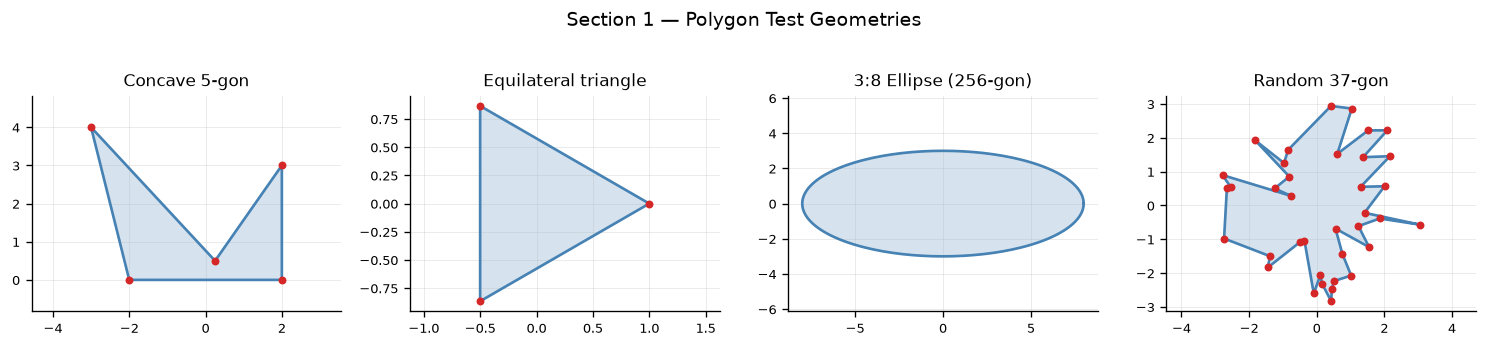

In [3]:
rng_poly = np.random.default_rng(42)

# 1. Concave 5-gon (Papaya2 test_imt.cpp)
concave_5 = np.array([
    [2.0, 3.0], [0.25, 0.5], [-3.0, 4.0], [-2.0, 0.0], [2.0, 0.0],
])

# 2. Equilateral triangle (unit circumradius)
eq_tri = np.array([
    [1.0, 0.0],
    [np.cos(2 * np.pi / 3), np.sin(2 * np.pi / 3)],
    [np.cos(-2 * np.pi / 3), np.sin(-2 * np.pi / 3)],
])

# 3. 3:8 ellipse (256 vertices)
phi_ell = np.linspace(0.0, 2 * np.pi, 256, endpoint=False)
ellipse_3_8 = np.column_stack([8.0 * np.cos(phi_ell), 3.0 * np.sin(phi_ell)])

# 4. Random 37-gon (star-shaped CCW)
angles_37 = np.sort(rng_poly.uniform(0.0, 2 * np.pi, size=37))
radii_37 = rng_poly.uniform(0.8, 3.5, size=37)
rand_37 = np.column_stack([radii_37 * np.cos(angles_37), radii_37 * np.sin(angles_37)])

POLYGONS = {
    "Concave 5-gon": concave_5,
    "Equilateral triangle": eq_tri,
    "3:8 Ellipse (256-gon)": ellipse_3_8,
    "Random 37-gon": rand_37,
}

poly_summary_rows = []
poly_results = {}
for name, verts in POLYGONS.items():
    c_res = cpp_polygon(verts)
    p_res = imt_polygon(verts)
    rec = record_comparison("Polygons", name, c_res, p_res)
    poly_results[name] = (c_res, p_res, rec)

    abs_errs = [rec[f"{f}_abs"] for f in ALL_FEATS]
    rel_nz = [rec[f"{f}_rel"] for f in ALL_FEATS if rec[f"{f}_scale"] > 1e-12]
    poly_summary_rows.append({
        "Polygon": name,
        "Vertices": len(verts),
        "Area": p_res["area"],
        "Perimeter": p_res["perimeter"],
        "beta102": p_res["beta102"],
        "isoper": p_res["isoper"],
        "Max |cpp - py|": max(abs_errs),
        "Max rel err (nonzero)": max(rel_nz),
    })

df_poly_sum = pd.DataFrame(poly_summary_rows).set_index("Polygon")
display(df_poly_sum.style.format({
    "Area": "{:.6f}", "Perimeter": "{:.6f}",
    "beta102": "{:.6f}", "isoper": "{:.6f}",
    "Max |cpp - py|": "{:.2e}", "Max rel err (nonzero)": "{:.2e}",
}))

# Side-by-side feature table for Concave 5-gon & Random 37-gon
for target in ["Concave 5-gon", "Random 37-gon"]:
    c_res, p_res, rec = poly_results[target]
    rows = []
    for f in ALL_FEATS:
        c_v, p_v = rec[f"{f}_cpp"], rec[f"{f}_py"]
        rows.append({
            "Feature": f,
            "C++ papaya2": f"{c_v.real:+.12e}{c_v.imag:+.12e}j" if isinstance(c_v, complex) else f"{c_v:.15e}",
            "pykarambola": f"{p_v.real:+.12e}{p_v.imag:+.12e}j" if isinstance(p_v, complex) else f"{p_v:.15e}",
            "|cpp - py|": f"{rec[f'{f}_abs']:.2e}",
            "rel_err": f"{rec[f'{f}_rel']:.2e}",
        })
    print(f"\n=== Side-by-side comparison: {target} ===")
    display(pd.DataFrame(rows).set_index("Feature"))

# Visual overview of the 4 test polygons
fig, axes = plt.subplots(1, 4, figsize=(12.5, 2.8))
for ax, (name, verts) in zip(axes, POLYGONS.items()):
    closed = np.vstack([verts, verts[0]])
    ax.fill(closed[:, 0], closed[:, 1], color="steelblue", alpha=0.22)
    ax.plot(closed[:, 0], closed[:, 1], color="steelblue", lw=1.6)
    if len(verts) <= 40:
        ax.scatter(verts[:, 0], verts[:, 1], s=14, color="#d62728", zorder=4)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(name, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Section 1 — Polygon Test Geometries", fontsize=11.5, y=1.02)
plt.tight_layout()
plt.show()

assert df_poly_sum["Max |cpp - py|"].max() < 1e-12


---
## Section 2 — Exhaustive 16 Marching-Squares Neighborhoods × 8 Flag Combos (128 Runs)

Every 2×2 binary neighborhood configuration ($2^4 = 16$ LUT cases) is evaluated
with anisotropic pixel spacing $\Delta x = 1.7, \Delta y = 2.3$ and an
asymmetric threshold $t = 0.37$ (exercising non-midpoint linear edge
interpolation alongside regular binarized marching squares) across all $2^3 = 8$
flag combinations:

- `method` $\in \{\text{interpolated}, \text{regular}\}$
- `analyze` $\in \{\text{white}, \text{black}\}$
- `connect` $\in \{\text{white}, \text{black}\}$ (saddle disambiguation for cases 6 and 9)

Total: **$16 \times 8 = 128$** head-to-head runs against C++ `papaya2`.


In [4]:
DX_LUT, DY_LUT = 1.7, 2.3
THR_LUT = 0.37

lut_rows = []
for method in ("interpolated", "regular"):
    for analyze in ("white", "black"):
        for connect in ("white", "black"):
            combo_abs = {"area": 0.0, "perimeter": 0.0, "q": 0.0, "psi": 0.0}
            combo_rel_nz = 0.0
            for bits in range(16):
                # 2x2 neighborhood in (x, y) order: (0,0), (0,1), (1,0), (1,1)
                arr = np.array([
                    [float((bits >> 0) & 1), float((bits >> 1) & 1)],
                    [float((bits >> 2) & 1), float((bits >> 3) & 1)],
                ], dtype=np.float64)
                c_res = cpp_image(
                    arr, dx=DX_LUT, dy=DY_LUT, threshold=THR_LUT,
                    boundary=None, method=method, analyze=analyze, connect=connect,
                )
                p_res = imt_image(
                    arr, threshold=THR_LUT, spacing=(DX_LUT, DY_LUT),
                    boundary=None, method=method, analyze=analyze, connect=connect,
                    xy_order=True,
                )
                case_id = f"b{bits:02d}_{method[:3]}_{analyze[0]}{connect[0]}"
                rec = record_comparison("MS 16x8 LUT", case_id, c_res, p_res)

                combo_abs["area"] = max(combo_abs["area"], rec["area_abs"])
                combo_abs["perimeter"] = max(combo_abs["perimeter"], rec["perimeter_abs"])
                combo_abs["q"] = max(combo_abs["q"], max(rec[f"{f}_abs"] for f in Q_FEATS))
                combo_abs["psi"] = max(combo_abs["psi"], max(rec[f"{f}_abs"] for f in PSI_FEATS))
                nz = [rec[f"{f}_rel"] for f in ALL_FEATS if rec[f"{f}_scale"] > 1e-12]
                if nz:
                    combo_rel_nz = max(combo_rel_nz, max(nz))

            lut_rows.append({
                "method": method,
                "analyze": analyze,
                "connect": connect,
                "cases": 16,
                "max |Δarea|": combo_abs["area"],
                "max |Δperim|": combo_abs["perimeter"],
                "max |Δq|": combo_abs["q"],
                "max |Δpsi|": combo_abs["psi"],
                "max rel (nonzero)": combo_rel_nz,
            })

df_lut = pd.DataFrame(lut_rows)
print(f"Total exhaustive LUT runs verified: {df_lut['cases'].sum()} (dx={DX_LUT}, dy={DY_LUT}, thr={THR_LUT})")
display(df_lut.style.format({
    "max |Δarea|": "{:.2e}",
    "max |Δperim|": "{:.2e}",
    "max |Δq|": "{:.2e}",
    "max |Δpsi|": "{:.2e}",
    "max rel (nonzero)": "{:.2e}",
}))

assert df_lut[["max |Δarea|", "max |Δperim|", "max |Δq|", "max |Δpsi|"]].to_numpy().max() < 1e-13


Total exhaustive LUT runs verified: 128 (dx=1.7, dy=2.3, thr=0.37)


,method,analyze,connect,cases,max |Δarea|,max |Δperim|,max |Δq|,max |Δpsi|,max rel (nonzero)
0,interpolated,white,white,16,1.33e-15,2.22e-16,2.78e-15,5.98e-15,3.32e-15
1,interpolated,white,black,16,8.88e-16,2.22e-16,2.78e-15,1.00e-14,3.32e-15
2,interpolated,black,white,16,8.88e-16,2.22e-16,2.78e-15,5.98e-15,3.32e-15
3,interpolated,black,black,16,8.88e-16,2.22e-16,2.78e-15,1.00e-14,3.32e-15
4,regular,white,white,16,8.88e-16,2.22e-16,2.11e-15,6.67e-15,2.33e-15
5,regular,white,black,16,8.88e-16,2.22e-16,2.11e-15,6.67e-15,2.33e-15
6,regular,black,white,16,8.88e-16,2.22e-16,2.11e-15,6.67e-15,2.33e-15
7,regular,black,black,16,8.88e-16,2.22e-16,2.11e-15,6.67e-15,2.33e-15


---
## Section 3 — `potato.png` Golden Grayscale Image, Minkowski Map & Multi-Threshold Sweep

We validate against Papaya2's golden grayscale fixture
[`tests/fixtures/potato.png`](../fixtures/potato.png)
($302 \times 361$ pixels, threshold $t = 146.9734492275599$):

1. **Exact comparison across $s = 2\text{--}12$** for both Papaya2 Cartesian
   `xy_order=True` and `pykarambola`'s default `(row, col)` bioimage convention
   (`xy_order=False`, where all scalars and rotation invariants $q_s$ match
   identically and $\psi_s^{(\text{rc})} = \overline{\psi_s^{(\text{xy})}}$).
2. **Spatially resolved Minkowski map $\psi_2(x, y)$** compared pixel-for-pixel
   against C++ `minkowski_map_interpolated_marching_squares`.
3. **25-threshold excursion-set curve** ($t \in [10, 245]$) comparing vectorized
   multi-threshold `imt_image` against C++ `papaya2` (`PingFile`) with residuals.


potato.png golden comparison at threshold = 146.973449228 (shape xy=(302, 361), rc=(361, 302))


,C++ papaya2,Py (xy_order=True),"Py (row, col)",|cpp - py_xy|,|cpp - py_rc|
Quantity,,,,,
area,7.760018008531e+04,7.760018008531e+04,7.760018008531e+04,3.20e-10,3.20e-10
perimeter,1.009820521813e+03,1.009820521813e+03,1.009820521813e+03,0.00e+00,1.14e-13
beta102,7.295489868751e-01,7.295489868751e-01,7.295489868751e-01,1.11e-16,1.11e-16
isoper,9.562780968806e-01,9.562780968806e-01,9.562780968806e-01,3.77e-15,4.00e-15
q2,1.563708314580e-01,1.563708314580e-01,1.563708314580e-01,1.11e-16,8.33e-17
q3,3.980635759576e-02,3.980635759576e-02,3.980635759576e-02,6.25e-17,6.25e-17
q4,1.481665040254e-01,1.481665040254e-01,1.481665040254e-01,5.55e-17,2.78e-17
q5,1.922804813953e-01,1.922804813953e-01,1.922804813953e-01,1.11e-16,1.11e-16
q6,1.454253098691e-01,1.454253098691e-01,1.454253098691e-01,4.16e-16,3.89e-16


potato.png Minkowski map (s=2, (301, 360) cells): max |cpp - py| = 5.66e-16


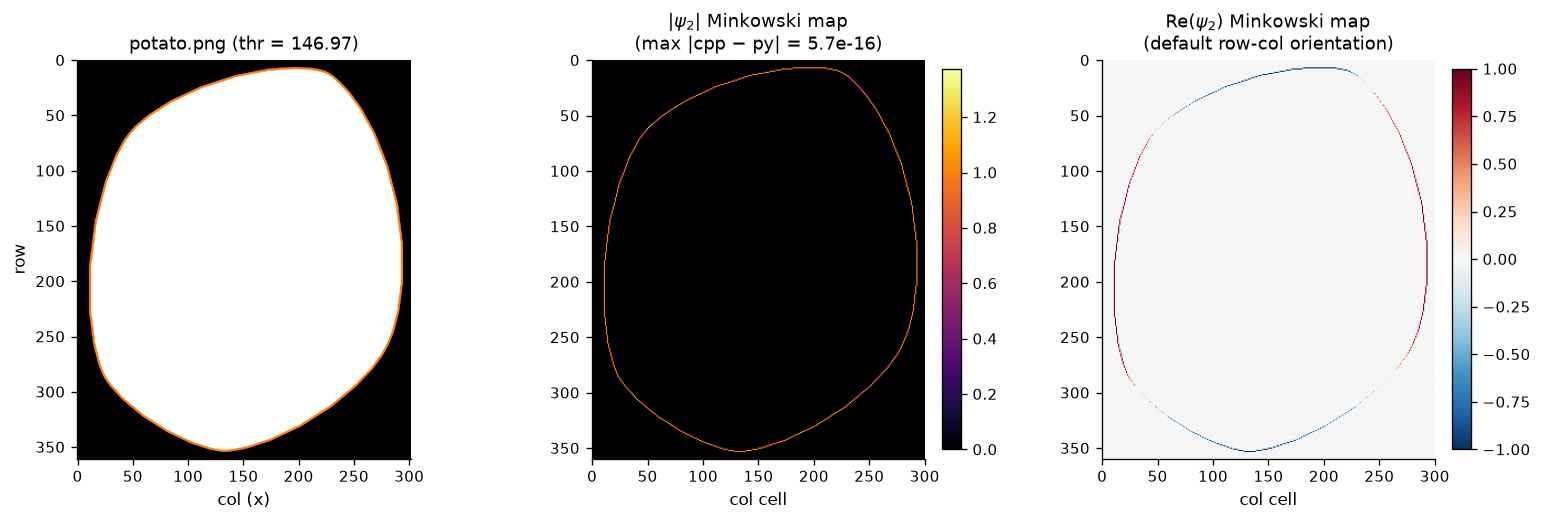

In [5]:
POTATO_PNG = os.path.abspath("../fixtures/potato.png")
raw_rgb = np.asarray(Image.open(POTATO_PNG))
raw_rc = (raw_rgb[:, :, 0] if raw_rgb.ndim == 3 else raw_rgb).astype(np.float64)
# Papaya2 PingFile Cartesian layout: x = col, y = H - 1 - row -> shape (302, 361)
potato_xy = raw_rc.T[:, ::-1].copy()
THR_GOLDEN = 1.469734492275599e2

cpp_pot = cpp_potato(POTATO_PNG, THR_GOLDEN)
py_pot_xy = imt_image(potato_xy, threshold=THR_GOLDEN, boundary=0.0, xy_order=True)
py_pot_rc = imt_image(raw_rc, threshold=THR_GOLDEN, boundary=0.0, xy_order=False)

# Exact comparison table (scalars + s = 2..12)
pot_rows = []
for k in SCALAR_FEATS:
    pot_rows.append({
        "Quantity": k,
        "C++ papaya2": f"{cpp_pot[k]:.12e}",
        "Py (xy_order=True)": f"{py_pot_xy[k]:.12e}",
        "Py (row, col)": f"{py_pot_rc[k]:.12e}",
        "|cpp - py_xy|": f"{abs(cpp_pot[k] - py_pot_xy[k]):.2e}",
        "|cpp - py_rc|": f"{abs(cpp_pot[k] - py_pot_rc[k]):.2e}",
    })
for s in range(2, 13):
    pot_rows.append({
        "Quantity": f"q{s}",
        "C++ papaya2": f"{cpp_pot['q'][s]:.12e}",
        "Py (xy_order=True)": f"{py_pot_xy['q'][s]:.12e}",
        "Py (row, col)": f"{py_pot_rc['q'][s]:.12e}",
        "|cpp - py_xy|": f"{abs(cpp_pot['q'][s] - py_pot_xy['q'][s]):.2e}",
        "|cpp - py_rc|": f"{abs(cpp_pot['q'][s] - py_pot_rc['q'][s]):.2e}",
    })
for s in range(2, 13):
    c_v = cpp_pot["psi"][s]
    p_xy = py_pot_xy["psi"][s]
    p_rc_conj = np.conj(py_pot_rc["psi"][s])
    pot_rows.append({
        "Quantity": f"psi{s}",
        "C++ papaya2": f"{c_v.real:+.9e}{c_v.imag:+.9e}j",
        "Py (xy_order=True)": f"{p_xy.real:+.9e}{p_xy.imag:+.9e}j",
        "Py (row, col)": f"{py_pot_rc['psi'][s].real:+.9e}{py_pot_rc['psi'][s].imag:+.9e}j (conj)",
        "|cpp - py_xy|": f"{abs(c_v - p_xy):.2e}",
        "|cpp - py_rc|": f"{abs(c_v - p_rc_conj):.2e}",
    })

print(f"potato.png golden comparison at threshold = {THR_GOLDEN:.12g} (shape xy={potato_xy.shape}, rc={raw_rc.shape})")
display(pd.DataFrame(pot_rows).set_index("Quantity"))

# Minkowski map (s = 2) verified pixel-by-pixel against C++ papaya2
cpp_pot_map = cpp_mmap(potato_xy, threshold=THR_GOLDEN, boundary=None, s=2)
py_pot_map_xy = minkowski_map(potato_xy, threshold=THR_GOLDEN, s=2, boundary=None, xy_order=True)
pot_map_err = np.max(np.abs(cpp_pot_map - py_pot_map_xy))
print(f"potato.png Minkowski map (s=2, {py_pot_map_xy.shape} cells): max |cpp - py| = {pot_map_err:.2e}")
assert pot_map_err < 1e-13

# Visual panel in natural (row, col) image orientation
py_pot_map_rc = minkowski_map(raw_rc, threshold=THR_GOLDEN, s=2, boundary=None, xy_order=False)
mag_map = np.abs(py_pot_map_rc)
re_map = np.real(py_pot_map_rc)
vmax_re = np.max(np.abs(re_map))

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.4))

axes[0].imshow(raw_rc, cmap="gray", origin="upper")
axes[0].contour(raw_rc, levels=[THR_GOLDEN], colors=["#ff7f0e"], linewidths=1.3)
axes[0].set_title(f"potato.png (thr = {THR_GOLDEN:.2f})")
axes[0].set_xlabel("col (x)")
axes[0].set_ylabel("row")
axes[0].grid(False)

im1 = axes[1].imshow(mag_map, cmap="inferno", origin="upper")
axes[1].set_title(r"$|\psi_2|$ Minkowski map" + f"\n(max |cpp − py| = {pot_map_err:.1e})")
axes[1].set_xlabel("col cell")
axes[1].grid(False)
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(re_map, cmap="RdBu_r", vmin=-vmax_re, vmax=vmax_re, origin="upper")
axes[2].set_title(r"$\mathrm{Re}(\psi_2)$ Minkowski map" + "\n(default row-col orientation)")
axes[2].set_xlabel("col cell")
axes[2].grid(False)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


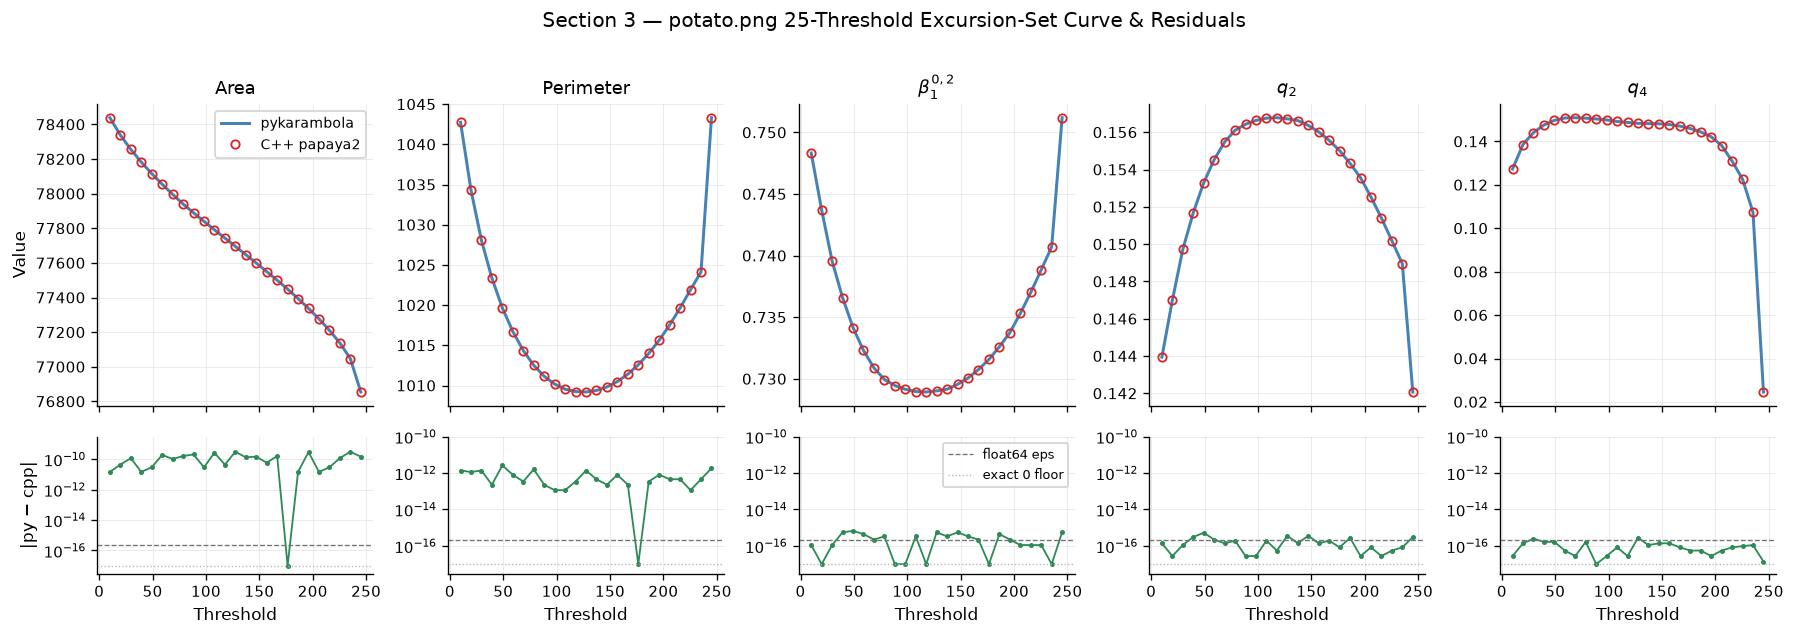

Across all 25 thresholds × 26 features: max |cpp - py| = 3.06e-10 (area ~ 1e5), max rel err = 4.92e-14


In [6]:
# ── 25-threshold excursion-set curve on potato.png ───────────────────────────
THRS_SWEEP = np.linspace(10.0, 245.0, 25)

# Vectorized single-call multi-threshold API in pykarambola
py_sweep = imt_image(potato_xy, threshold=THRS_SWEEP, boundary=0.0, xy_order=True)
cpp_sweep = [cpp_potato(POTATO_PNG, t) for t in THRS_SWEEP]

for idx, (t, c_res) in enumerate(zip(THRS_SWEEP, cpp_sweep)):
    p_res = {
        "area": float(py_sweep["area"][idx]),
        "perimeter": float(py_sweep["perimeter"][idx]),
        "beta102": float(py_sweep["beta102"][idx]),
        "isoper": float(py_sweep["isoper"][idx]),
        "psi": py_sweep["psi"][idx],
        "q": py_sweep["q"][idx],
    }
    record_comparison("potato.png sweep", f"thr_{t:.1f}", c_res, p_res)

SWEEP_KEYS = [
    ("area", "Area", lambda r: r["area"], py_sweep["area"]),
    ("perimeter", "Perimeter", lambda r: r["perimeter"], py_sweep["perimeter"]),
    ("beta102", r"$\beta_1^{0,2}$", lambda r: r["beta102"], py_sweep["beta102"]),
    ("q2", r"$q_2$", lambda r: r["q"][2], py_sweep["q"][:, 2]),
    ("q4", r"$q_4$", lambda r: r["q"][4], py_sweep["q"][:, 4]),
]

RESID_FLOOR = 1e-17
fig, axes = plt.subplots(
    2, 5, figsize=(15.0, 5.2), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0]},
)

for col, (key, label, c_getter, p_arr) in enumerate(SWEEP_KEYS):
    c_arr = np.array([c_getter(r) for r in cpp_sweep], dtype=np.float64)
    diff = np.abs(p_arr - c_arr)

    ax_top = axes[0, col]
    ax_top.plot(THRS_SWEEP, p_arr, color="steelblue", lw=1.8, label="pykarambola")
    ax_top.plot(THRS_SWEEP, c_arr, "o", mfc="none", mec="#d62728", ms=5.0, mew=1.1, label="C++ papaya2")
    ax_top.set_title(label, fontsize=11)
    if col == 0:
        ax_top.set_ylabel("Value")
        ax_top.legend(loc="best", frameon=True, framealpha=0.85)

    ax_bot = axes[1, col]
    ax_bot.semilogy(THRS_SWEEP, np.maximum(diff, RESID_FLOOR), ".-", color="seagreen", lw=1.1, ms=4)
    ax_bot.axhline(np.finfo(float).eps, color="0.45", ls="--", lw=0.8, label="float64 eps")
    ax_bot.axhline(RESID_FLOOR, color="0.7", ls=":", lw=0.8, label="exact 0 floor")
    ax_bot.set_ylim(3e-18, max(1e-10, float(np.nanmax(diff)) * 10))
    ax_bot.set_xlabel("Threshold")
    if col == 0:
        ax_bot.set_ylabel("|py − cpp|")
    if col == 2:
        ax_bot.legend(loc="upper right", fontsize=7.5, frameon=True, framealpha=0.88)

fig.suptitle("Section 3 — potato.png 25-Threshold Excursion-Set Curve & Residuals", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

sweep_recs = [r for r in ALL_RECORDS if r["suite"] == "potato.png sweep"]
max_sweep_err = max(r[f"{f}_abs"] for r in sweep_recs for f in ALL_FEATS)
max_sweep_rel = max(
    r[f"{f}_rel"] for r in sweep_recs for f in ALL_FEATS if r[f"{f}_scale"] > 1e-12
)
print(
    f"Across all 25 thresholds × 26 features: "
    f"max |cpp - py| = {max_sweep_err:.2e} (area ~ 1e5), max rel err = {max_sweep_rel:.2e}"
)
assert max_sweep_rel < 1e-12 and max_sweep_err < 1e-9


---
## Section 4 — Comprehensive Error Diagnostics (64×48 Random Grayscale × 24 Modes + 15 Minkowski Maps)

To stress-test every code path simultaneously, we evaluate a 64×48 random
grayscale image with anisotropic pixel spacing $(\Delta x = 1.3, \Delta y = 0.85)$
across:

- **24 IMT mode/flag combinations**: `boundary` $\in \{\text{None}, 0.0, \text{'periodic'}\}$ × `method` $\in \{\text{interpolated}, \text{regular}\}$ × `analyze` $\in \{\text{white}, \text{black}\}$ × `connect` $\in \{\text{white}, \text{black}\}$.
- **15 Minkowski maps**: `boundary` $\in \{\text{None}, 0.0, \text{'periodic'}\}$ × $s \in \{0, 2, 3, 4, 6\}$, verified pixel-by-pixel against C++ `papaya2`.

We then aggregate all **181 full IMT comparisons** across Sections 1–4
(4 Polygons + 128 Exhaustive LUT + 25 `potato.png` sweep + 24 Random 64×48)
into the standard `pykarambola` validation suite:
**Figure 1** (validation scatter with $y = x$), **Figure 2** (log-scale error
bar chart), **Figure 3** (suite × feature relative-error heatmap), and a
per-feature **Summary Table**.


In [7]:
rng_diag = np.random.default_rng(2026)
rand_img = rng_diag.uniform(0.0, 1.0, size=(64, 48))
DX_R, DY_R, THR_R = 1.3, 0.85, 0.43

# ── 24 mode/flag combinations on 64x48 random grayscale ──────────────────────
for boundary in (None, 0.0, "periodic"):
    b_tag = "none" if boundary is None else ("per" if boundary == "periodic" else "pad0")
    for method in ("interpolated", "regular"):
        for analyze in ("white", "black"):
            for connect in ("white", "black"):
                c_res = cpp_image(
                    rand_img, dx=DX_R, dy=DY_R, threshold=THR_R,
                    boundary=boundary, method=method, analyze=analyze, connect=connect,
                )
                p_res = imt_image(
                    rand_img, threshold=THR_R, spacing=(DX_R, DY_R),
                    boundary=boundary, method=method, analyze=analyze, connect=connect,
                    xy_order=True,
                )
                cid = f"{b_tag}_{method[:3]}_{analyze[0]}{connect[0]}"
                record_comparison("Random 64x48 (24x)", cid, c_res, p_res)

# ── 15 Minkowski maps (3 boundaries x 5 angular orders) ──────────────────────
mmap_rows = []
total_mmap_pixels = 0
for boundary in (None, 0.0, "periodic"):
    for s in (0, 2, 3, 4, 6):
        c_map = cpp_mmap(rand_img, dx=DX_R, dy=DY_R, threshold=THR_R, boundary=boundary, s=s)
        p_map = minkowski_map(
            rand_img, threshold=THR_R, s=s, spacing=(DX_R, DY_R),
            boundary=boundary, xy_order=True,
        )
        assert c_map.shape == p_map.shape
        diff = np.abs(c_map - p_map)
        denom = np.maximum(np.abs(c_map), np.abs(p_map))
        rel = np.where(denom > 1e-12, diff / np.where(denom > 0, denom, 1.0), 0.0)
        total_mmap_pixels += c_map.size
        mmap_rows.append({
            "boundary": str(boundary),
            "s": s,
            "shape": str(c_map.shape),
            "pixels": c_map.size,
            "nonzero_cells": int(np.count_nonzero(denom > 0)),
            "max |cpp - py|": float(diff.max()),
            "max rel (nonzero)": float(rel.max()),
        })

df_mmap = pd.DataFrame(mmap_rows)
print(f"Verified 24 IMT mode/flag combos + 15 Minkowski maps ({total_mmap_pixels:,} complex pixels)")
display(df_mmap.style.format({"max |cpp - py|": "{:.2e}", "max rel (nonzero)": "{:.2e}"}))
assert df_mmap["max |cpp - py|"].max() < 1e-13

df_all = pd.DataFrame(ALL_RECORDS)
print(f"\nUnified diagnostic dataset: {len(df_all)} full IMT comparisons across {df_all['suite'].nunique()} suites:")
print(df_all["suite"].value_counts().to_string())


Verified 24 IMT mode/flag combos + 15 Minkowski maps (46,090 complex pixels)


,boundary,s,shape,pixels,nonzero_cells,max |cpp - py|,max rel (nonzero)
0,None,0,"(63, 47)",2961,2570,6.66e-16,1.84e-13
1,None,2,"(63, 47)",2961,2570,1.26e-15,3.56e-13
2,None,3,"(63, 47)",2961,2570,1.62e-15,4.93e-13
3,None,4,"(63, 47)",2961,2570,2.32e-15,6.37e-13
4,None,6,"(63, 47)",2961,2570,3.58e-15,9.33e-13
5,0.0,0,"(65, 49)",3185,2753,6.66e-16,1.84e-13
6,0.0,2,"(65, 49)",3185,2753,1.26e-15,3.56e-13
7,0.0,3,"(65, 49)",3185,2753,1.62e-15,4.93e-13
8,0.0,4,"(65, 49)",3185,2753,2.32e-15,6.37e-13
9,0.0,6,"(65, 49)",3185,2753,3.58e-15,9.33e-13



Unified diagnostic dataset: 181 full IMT comparisons across 4 suites:
suite
MS 16x8 LUT           128
potato.png sweep       25
Random 64x48 (24x)     24
Polygons                4


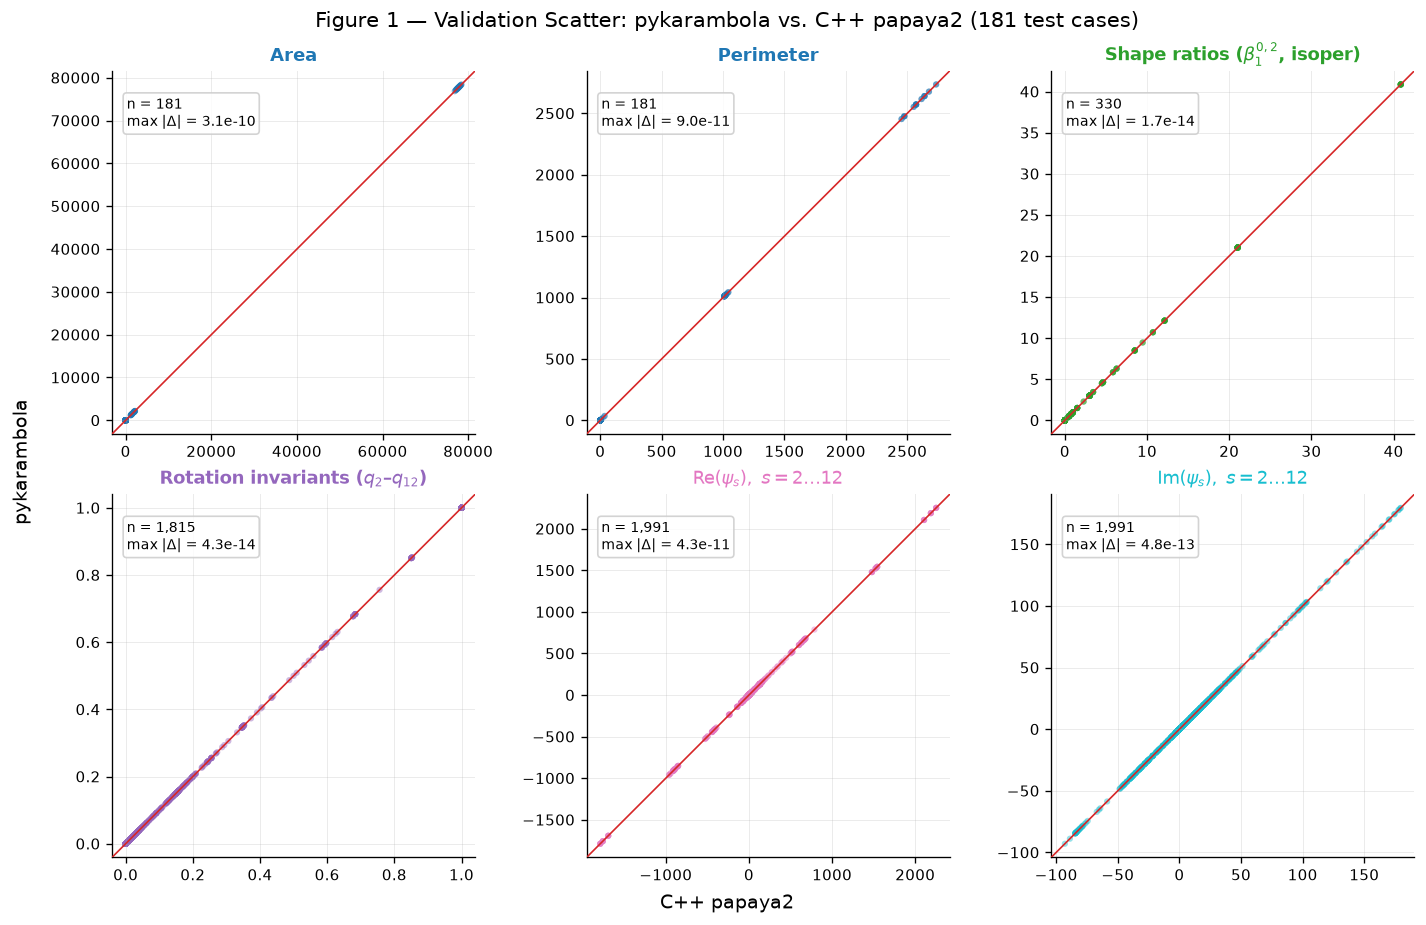

In [8]:
# ── Figure 1 — Validation scatter: pykarambola vs C++ papaya2 (y = x) ────────
SCATTER_PANELS = [
    ("Area", ["area"], "real", "#1f77b4"),
    ("Perimeter", ["perimeter"], "real", "#1f77b4"),
    (r"Shape ratios ($\beta_1^{0,2}$, isoper)", ["beta102", "isoper"], "real", "#2ca02c"),
    (r"Rotation invariants ($q_2$–$q_{12}$)", Q_FEATS, "real", "#9467bd"),
    (r"$\mathrm{Re}(\psi_s),\ s=2\ldots 12$", PSI_FEATS, "re", "#e377c2"),
    (r"$\mathrm{Im}(\psi_s),\ s=2\ldots 12$", PSI_FEATS, "im", "#17becf"),
]

fig, axes = plt.subplots(2, 3, figsize=(12.0, 7.6), constrained_layout=True)

for ax, (title, feats, mode, color) in zip(axes.ravel(), SCATTER_PANELS):
    c_list, p_list = [], []
    for f in feats:
        cv = df_all[f"{f}_cpp"].to_numpy()
        pv = df_all[f"{f}_py"].to_numpy()
        if mode == "re":
            cv, pv = np.real(cv), np.real(pv)
        elif mode == "im":
            cv, pv = np.imag(cv), np.imag(pv)
        else:
            cv, pv = cv.astype(np.float64), pv.astype(np.float64)
        mask = np.isfinite(cv) & np.isfinite(pv)
        c_list.append(cv[mask])
        p_list.append(pv[mask])

    c_all = np.concatenate(c_list)
    p_all = np.concatenate(p_list)
    lo = min(c_all.min(), p_all.min())
    hi = max(c_all.max(), p_all.max())
    pad = 0.04 * (hi - lo if hi > lo else 1.0)

    ax.scatter(c_all, p_all, s=14, alpha=0.45, color=color, edgecolors="none", rasterized=True)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="#d62728", lw=1.0, ls="-", zorder=5, label="y = x")
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_box_aspect(1)
    ax.set_title(title, fontsize=10.5, color=color, fontweight="bold")
    max_d = np.max(np.abs(c_all - p_all))
    ax.text(
        0.04, 0.93, f"n = {len(c_all):,}\nmax |Δ| = {max_d:.1e}",
        transform=ax.transAxes, fontsize=8.5, va="top",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.85),
    )

fig.supxlabel("C++ papaya2", fontsize=11.5)
fig.supylabel("pykarambola", fontsize=11.5)
fig.suptitle(
    f"Figure 1 — Validation Scatter: pykarambola vs. C++ papaya2 ({len(df_all)} test cases)",
    fontsize=12.5,
)
plt.show()


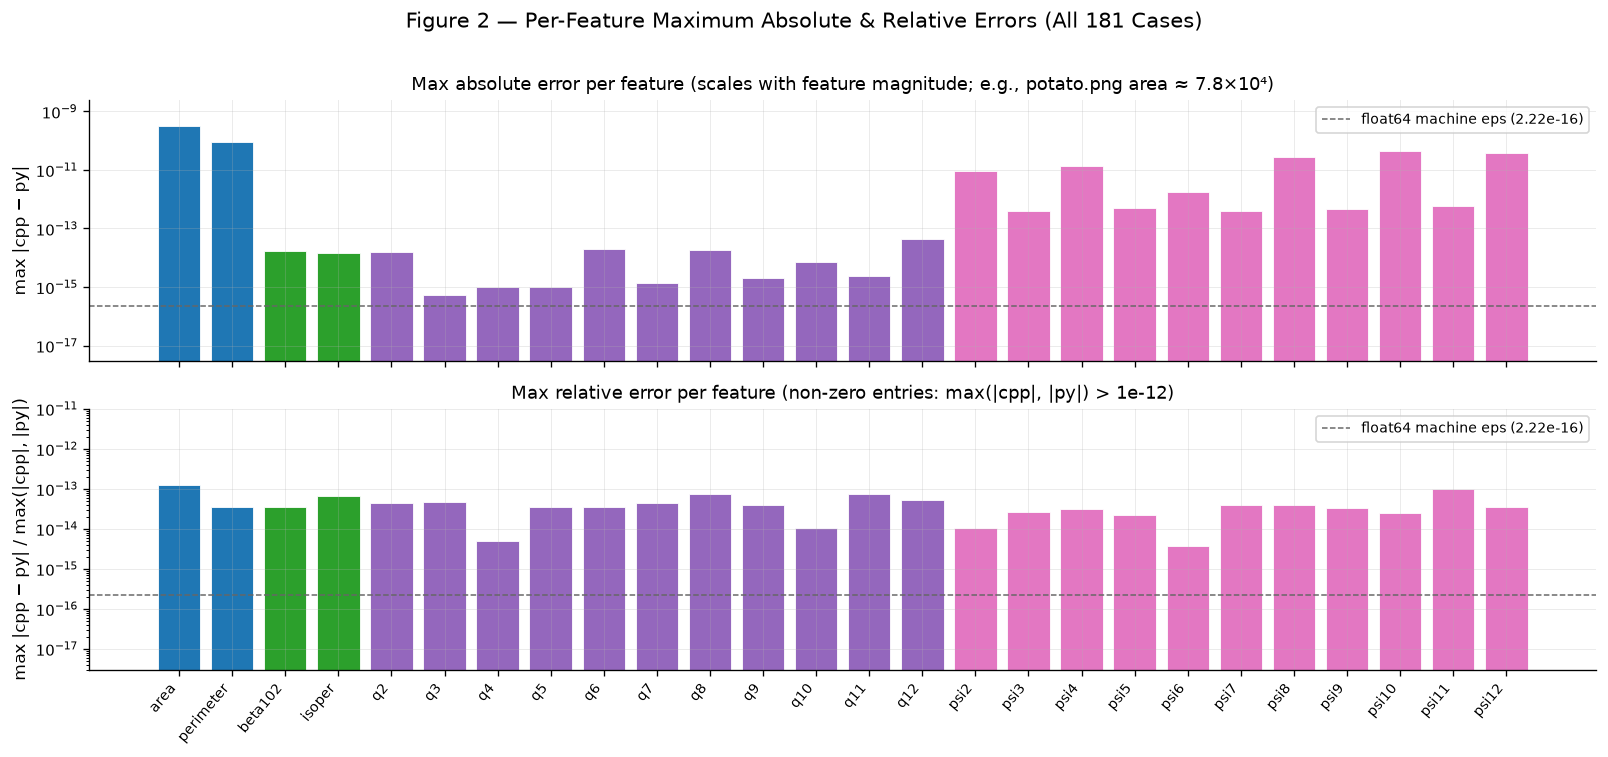

In [9]:
# ── Figure 2 — Log-scale bar chart: max absolute & relative error per feature
bar_rows = []
for f in ALL_FEATS:
    abs_arr = df_all[f"{f}_abs"].to_numpy(dtype=np.float64)
    rel_arr = df_all[f"{f}_rel"].to_numpy(dtype=np.float64)
    scale_arr = df_all[f"{f}_scale"].to_numpy(dtype=np.float64)
    nz_mask = scale_arr > 1e-12
    bar_rows.append({
        "feature": f,
        "max_abs": float(abs_arr.max()),
        "mean_abs": float(abs_arr.mean()),
        "max_rel_all": float(rel_arr.max()),
        "max_rel_nz": float(rel_arr[nz_mask].max()) if np.any(nz_mask) else 0.0,
        "mean_rel_nz": float(rel_arr[nz_mask].mean()) if np.any(nz_mask) else 0.0,
        "max_val": float(scale_arr.max()),
    })

df_feat_summary = pd.DataFrame(bar_rows).set_index("feature")

bar_colors = (
    ["#1f77b4", "#1f77b4", "#2ca02c", "#2ca02c"]
    + ["#9467bd"] * len(Q_FEATS)
    + ["#e377c2"] * len(PSI_FEATS)
)

x = np.arange(len(ALL_FEATS))
FLOOR = 1e-17

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13.5, 6.2), sharex=True)

ax1.bar(x, np.maximum(df_feat_summary["max_abs"], FLOOR), color=bar_colors, edgecolor="white", lw=0.5)
ax1.set_yscale("log")
ax1.axhline(np.finfo(float).eps, color="0.4", ls="--", lw=0.9, label="float64 machine eps (2.22e-16)")
ax1.set_ylim(3e-18, max(1e-9, df_feat_summary["max_abs"].max() * 8))
ax1.set_ylabel("max |cpp − py|")
ax1.set_title("Max absolute error per feature (scales with feature magnitude; e.g., potato.png area ≈ 7.8×10⁴)")
ax1.legend(loc="upper right")

ax2.bar(x, np.maximum(df_feat_summary["max_rel_nz"], FLOOR), color=bar_colors, edgecolor="white", lw=0.5)
ax2.set_yscale("log")
ax2.axhline(np.finfo(float).eps, color="0.4", ls="--", lw=0.9, label="float64 machine eps (2.22e-16)")
ax2.set_ylim(3e-18, max(1e-11, df_feat_summary["max_rel_nz"].max() * 10))
ax2.set_ylabel("max |cpp − py| / max(|cpp|, |py|)")
ax2.set_title("Max relative error per feature (non-zero entries: max(|cpp|, |py|) > 1e-12)")
ax2.set_xticks(x)
ax2.set_xticklabels(ALL_FEATS, rotation=50, ha="right", fontsize=8.5)
ax2.legend(loc="upper right")

fig.suptitle("Figure 2 — Per-Feature Maximum Absolute & Relative Errors (All 181 Cases)", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()


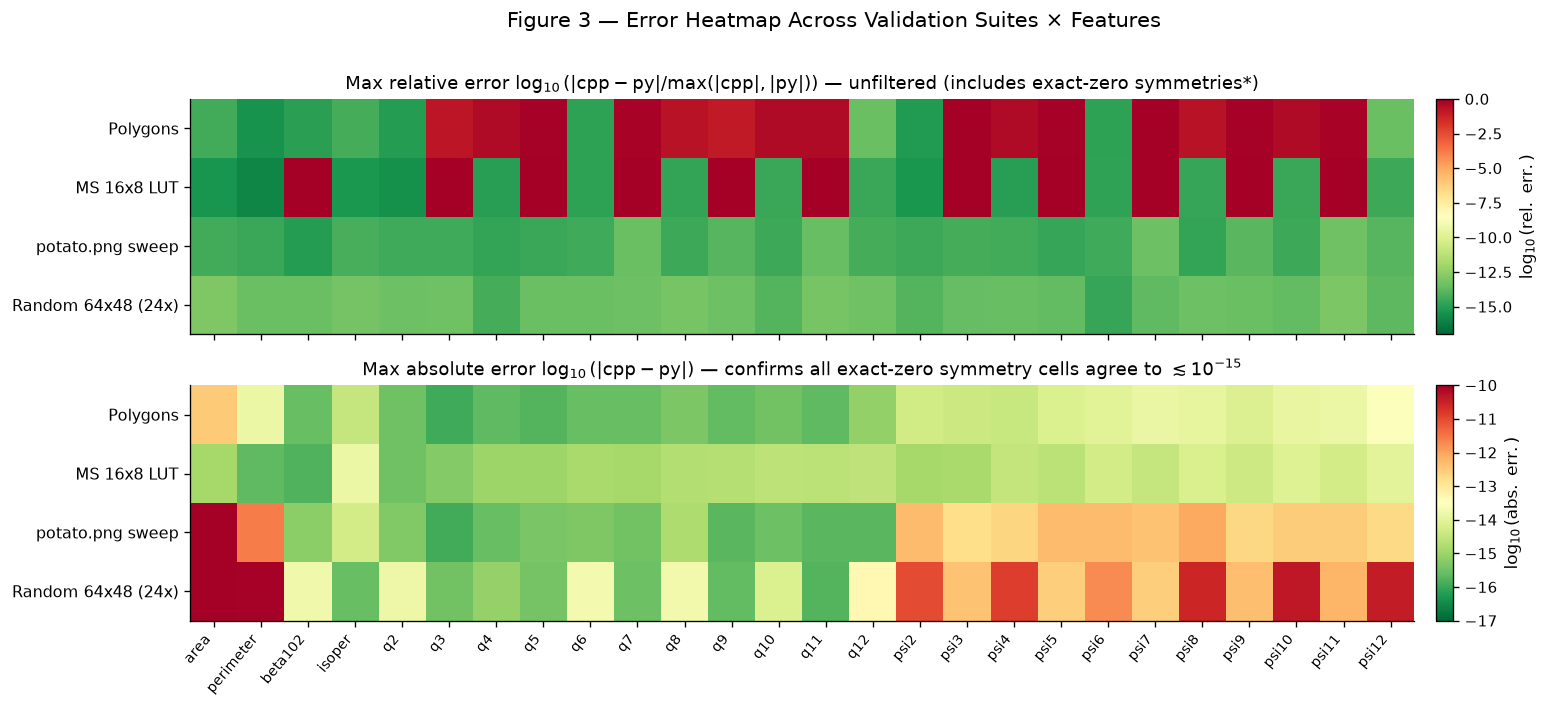

In [10]:
# ── Figure 3 — Error heatmap: relative error & absolute error (suites × features)
SUITE_ORDER = ["Polygons", "MS 16x8 LUT", "potato.png sweep", "Random 64x48 (24x)"]

rel_matrix = np.zeros((len(SUITE_ORDER), len(ALL_FEATS)), dtype=np.float64)
abs_matrix = np.zeros((len(SUITE_ORDER), len(ALL_FEATS)), dtype=np.float64)

for i, suite in enumerate(SUITE_ORDER):
    sub = df_all[df_all["suite"] == suite]
    for j, f in enumerate(ALL_FEATS):
        rel_matrix[i, j] = sub[f"{f}_rel"].max()
        abs_matrix[i, j] = sub[f"{f}_abs"].max()

# Display log10(error) with clean floor at -17 so exact 0s render cleanly at the bottom of the scale
rel_log = np.log10(np.maximum(rel_matrix, 1e-17))
abs_log = np.log10(np.maximum(abs_matrix, 1e-17))

fig, (ax_r, ax_a) = plt.subplots(2, 1, figsize=(14.0, 5.8), sharex=True)

im_r = ax_r.imshow(rel_log, aspect="auto", cmap="RdYlGn_r", vmin=-17, vmax=0)
ax_r.set_yticks(range(len(SUITE_ORDER)))
ax_r.set_yticklabels(SUITE_ORDER, fontsize=9.5)
ax_r.set_title(r"Max relative error $\log_{10}(|\mathrm{cpp} - \mathrm{py}| / \max(|\mathrm{cpp}|, |\mathrm{py}|))$ — unfiltered (includes exact-zero symmetries*)")
ax_r.grid(False)
cbar_r = fig.colorbar(im_r, ax=ax_r, pad=0.015, aspect=14)
cbar_r.set_label(r"$\log_{10}(\mathrm{rel.\ err.})$")

im_a = ax_a.imshow(abs_log, aspect="auto", cmap="RdYlGn_r", vmin=-17, vmax=-10)
ax_a.set_yticks(range(len(SUITE_ORDER)))
ax_a.set_yticklabels(SUITE_ORDER, fontsize=9.5)
ax_a.set_xticks(range(len(ALL_FEATS)))
ax_a.set_xticklabels(ALL_FEATS, rotation=50, ha="right", fontsize=8.5)
ax_a.set_title(r"Max absolute error $\log_{10}(|\mathrm{cpp} - \mathrm{py}|)$ — confirms all exact-zero symmetry cells agree to $\lesssim 10^{-15}$")
ax_a.grid(False)
cbar_a = fig.colorbar(im_a, ax=ax_a, pad=0.015, aspect=14)
cbar_a.set_label(r"$\log_{10}(\mathrm{abs.\ err.})$")

fig.suptitle("Figure 3 — Error Heatmap Across Validation Suites × Features", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()


> **\*Note on relative error for near-zero entries:** Relative error is computed as
> $|\mathrm{cpp} - \mathrm{py}| / \max(|\mathrm{cpp}|, |\mathrm{py}|)$ (with $0 / 0 \equiv 0$).
> For features whose true mathematical value is identically zero on a given
> geometry—such as $q_s$ and $\psi_s$ with $s \not\equiv 0 \pmod 3$ on the
> equilateral triangle, odd-$s$ harmonics on the symmetric 3:8 ellipse, or
> $\beta_1^{0,2} = (1 - q_2)/(1 + q_2) = 0$ and odd-$s$ harmonics on symmetric
> 2×2 marching-squares stencils—both C++ `papaya2` and `pykarambola` evaluate
> floating-point cancellations near machine epsilon ($\sim 10^{-16}$).
> Dividing two distinct $\sim 10^{-16}$ residuals (potentially of opposite sign)
> produces an artificially large ratio (up to $1.0\text{--}2.0$) even though
> both implementations agree to $\lesssim 10^{-15}$ in absolute terms, as
> confirmed by the lower absolute-error panel in Figure 3. For exact-zero
> symmetries, the absolute error is the physically informative diagnostic.


In [11]:
# ── Summary Table: per-feature max/mean absolute and relative errors ─────────
summary_disp = df_feat_summary.rename(columns={
    "max_abs": "max |cpp - py|",
    "mean_abs": "mean |cpp - py|",
    "max_rel_nz": "max rel (nonzero)",
    "mean_rel_nz": "mean rel (nonzero)",
    "max_rel_all": "max rel (unfiltered)",
    "max_val": "max |value|",
})[["max |value|", "max |cpp - py|", "mean |cpp - py|", "max rel (nonzero)", "mean rel (nonzero)", "max rel (unfiltered)"]]

display(summary_disp.style.format("{:.3e}"))
print(
    f"\nOverall across {len(df_all)} IMT cases (nonzero entries > 1e-12): "
    f"max rel err = {df_feat_summary['max_rel_nz'].max():.3e}, "
    f"max abs err = {df_feat_summary['max_abs'].max():.3e}"
)
print(
    f"Overall across 15 Minkowski maps ({total_mmap_pixels:,} complex pixels): "
    f"max abs err = {df_mmap['max |cpp - py|'].max():.3e}"
)


,max |value|,max |cpp - py|,mean |cpp - py|,max rel (nonzero),mean rel (nonzero),max rel (unfiltered)
feature,,,,,,
area,7.844e+04,3.056e-10,2.828e-11,1.213e-13,7.668e-15,1.213e-13
perimeter,2.735e+03,9.004e-11,5.575e-12,3.410e-14,2.453e-15,3.410e-14
beta102,1.000e+00,1.693e-14,1.134e-15,3.483e-14,7.588e-15,1.500e+00
isoper,4.087e+01,1.421e-14,1.161e-15,6.565e-14,4.033e-15,6.565e-14
q2,1.000e+00,1.532e-14,1.073e-15,4.431e-14,3.313e-15,4.431e-14
q3,1.000e+00,5.551e-16,8.977e-17,4.643e-14,3.154e-15,1.000e+00
q4,1.000e+00,9.992e-16,2.608e-16,4.862e-15,6.083e-16,3.750e-01
q5,1.000e+00,9.992e-16,2.814e-16,3.482e-14,3.110e-15,1.000e+00
q6,1.000e+00,2.032e-14,1.615e-15,3.479e-14,2.971e-15,3.479e-14



Overall across 181 IMT cases (nonzero entries > 1e-12): max rel err = 1.213e-13, max abs err = 3.056e-10
Overall across 15 Minkowski maps (46,090 complex pixels): max abs err = 3.580e-15


---
## Section 5 — Rotated Ellipses (Orientation Robustness)

Paralleling the 3D ellipsoid orientation-bias analysis
(`paper/notebooks/orientation_bias_ellipsoid.ipynb`), we rasterize an 8:3
ellipse ($a = 40$, $b = 15$ pixels on a $128 \times 128$ grid via the smooth
level-set field $f(x, y) = 1 - \sqrt{(x'/a)^2 + (y'/b)^2}$ at threshold $0$)
across rotation angles $\theta \in [0^\circ, 90^\circ]$ in $5^\circ$ increments:

- **Interpolated marching squares** tracks the smooth sub-pixel boundary and
  recovers the analytic continuum values ($\beta_1^{0,2} \approx 0.2265$,
  $q_2 \approx 0.6307$) with minimal orientation drift.
- **Regular marching squares** binarizes $f \ge 0$ before contouring, introducing
  pronounced pixel-grid anisotropy bias ($\Delta \beta_1^{0,2} \approx 0.04$).
- At **every single orientation and for both methods**, `pykarambola` agrees
  with C++ `papaya2` to floating-point machine precision ($\sim 10^{-16}$).


Analytic 8:3 ellipse reference: beta102 = 0.226467, q2 = 0.630700


,beta102 mean,beta102 p2p drift,beta102 max |py-cpp|,q2 mean,q2 p2p drift,q2 max |py-cpp|
Method,,,,,,
interpolated,0.226552,0.000134,3.89e-16,0.630587,0.000178,5.55e-16
regular,0.326348,0.040185,1.50e-15,0.508059,0.045741,1.67e-15


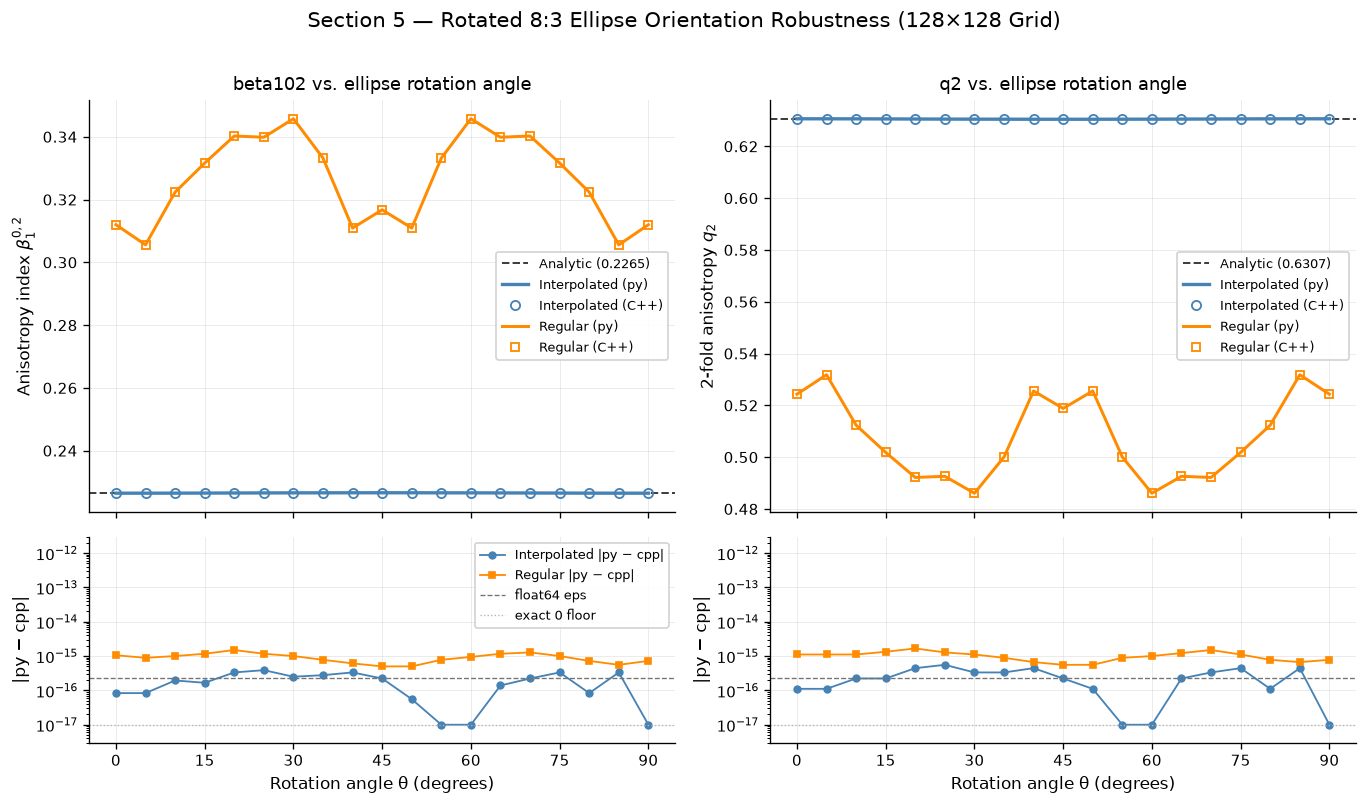

In [12]:
# Analytic continuum reference for 8:3 ellipse (20,000-vertex polygon)
phi_ref = np.linspace(0.0, 2 * np.pi, 20000, endpoint=False)
ell_ref = imt_polygon(np.column_stack([40.0 * np.cos(phi_ref), 15.0 * np.sin(phi_ref)]))
BETA_ANALYTIC = ell_ref["beta102"]
Q2_ANALYTIC = ell_ref["q"][2]

ANGLES_DEG = np.arange(0, 95, 5, dtype=np.float64)
coords = np.arange(128, dtype=np.float64) - 63.5
X_grid, Y_grid = np.meshgrid(coords, coords, indexing="ij")

rot_data = {m: {"py_b": [], "cpp_b": [], "py_q2": [], "cpp_q2": []} for m in ("interpolated", "regular")}

for deg in ANGLES_DEG:
    th = np.deg2rad(deg)
    xr = X_grid * np.cos(th) + Y_grid * np.sin(th)
    yr = -X_grid * np.sin(th) + Y_grid * np.cos(th)
    field = 1.0 - np.hypot(xr / 40.0, yr / 15.0)

    for method in ("interpolated", "regular"):
        p_res = imt_image(field, threshold=0.0, boundary=-1.0, method=method, xy_order=True)
        c_res = cpp_image(field, threshold=0.0, boundary=-1.0, method=method)
        rot_data[method]["py_b"].append(p_res["beta102"])
        rot_data[method]["cpp_b"].append(c_res["beta102"])
        rot_data[method]["py_q2"].append(p_res["q"][2])
        rot_data[method]["cpp_q2"].append(c_res["q"][2])

for m in rot_data:
    for k in rot_data[m]:
        rot_data[m][k] = np.array(rot_data[m][k], dtype=np.float64)

# Summary table of orientation bias & Python-vs-C++ agreement
rot_summary = []
for method in ("interpolated", "regular"):
    d = rot_data[method]
    rot_summary.append({
        "Method": method,
        "beta102 mean": d["py_b"].mean(),
        "beta102 p2p drift": np.ptp(d["py_b"]),
        "beta102 max |py-cpp|": np.max(np.abs(d["py_b"] - d["cpp_b"])),
        "q2 mean": d["py_q2"].mean(),
        "q2 p2p drift": np.ptp(d["py_q2"]),
        "q2 max |py-cpp|": np.max(np.abs(d["py_q2"] - d["cpp_q2"])),
    })

print(f"Analytic 8:3 ellipse reference: beta102 = {BETA_ANALYTIC:.6f}, q2 = {Q2_ANALYTIC:.6f}")
display(pd.DataFrame(rot_summary).set_index("Method").style.format({
    "beta102 mean": "{:.6f}", "beta102 p2p drift": "{:.6f}", "beta102 max |py-cpp|": "{:.2e}",
    "q2 mean": "{:.6f}", "q2 p2p drift": "{:.6f}", "q2 max |py-cpp|": "{:.2e}",
}))

# 2x2 plot: top = beta102 & q2 vs angle, bottom = Python-vs-C++ residuals
FLOOR_ROT = 1e-17
fig, axes = plt.subplots(
    2, 2, figsize=(11.5, 6.6), sharex=True,
    gridspec_kw={"height_ratios": [2.0, 1.0]},
)

for col, (metric, ylabel, ref_val, py_k, cpp_k) in enumerate([
    ("beta102", r"Anisotropy index $\beta_1^{0,2}$", BETA_ANALYTIC, "py_b", "cpp_b"),
    ("q2", r"2-fold anisotropy $q_2$", Q2_ANALYTIC, "py_q2", "cpp_q2"),
]):
    ax_t = axes[0, col]
    ax_t.axhline(ref_val, color="0.25", ls="--", lw=1.2, label=f"Analytic ({ref_val:.4f})")

    # Interpolated
    ax_t.plot(ANGLES_DEG, rot_data["interpolated"][py_k], color="steelblue", lw=2.0, label="Interpolated (py)")
    ax_t.plot(ANGLES_DEG, rot_data["interpolated"][cpp_k], "o", mfc="none", mec="steelblue", ms=5.5, mew=1.1, label="Interpolated (C++)")

    # Regular
    ax_t.plot(ANGLES_DEG, rot_data["regular"][py_k], color="darkorange", lw=1.8, label="Regular (py)")
    ax_t.plot(ANGLES_DEG, rot_data["regular"][cpp_k], "s", mfc="none", mec="darkorange", ms=5.0, mew=1.1, label="Regular (C++)")

    ax_t.set_ylabel(ylabel)
    ax_t.set_title(f"{metric} vs. ellipse rotation angle")
    ax_t.legend(loc="best", fontsize=8, frameon=True, framealpha=0.88)

    ax_b = axes[1, col]
    r_int = np.abs(rot_data["interpolated"][py_k] - rot_data["interpolated"][cpp_k])
    r_reg = np.abs(rot_data["regular"][py_k] - rot_data["regular"][cpp_k])
    ax_b.semilogy(ANGLES_DEG, np.maximum(r_int, FLOOR_ROT), "o-", color="steelblue", ms=4, lw=1.1, label="Interpolated |py − cpp|")
    ax_b.semilogy(ANGLES_DEG, np.maximum(r_reg, FLOOR_ROT), "s-", color="darkorange", ms=4, lw=1.1, label="Regular |py − cpp|")
    ax_b.axhline(np.finfo(float).eps, color="0.45", ls="--", lw=0.8, label="float64 eps")
    ax_b.axhline(FLOOR_ROT, color="0.7", ls=":", lw=0.8, label="exact 0 floor")
    ax_b.set_ylim(3e-18, 3e-12)
    ax_b.set_xlabel("Rotation angle θ (degrees)")
    ax_b.set_ylabel("|py − cpp|")
    ax_b.set_xticks(np.arange(0, 95, 15))
    if col == 0:
        ax_b.legend(loc="upper right", fontsize=7.5, frameon=True, framealpha=0.88)

fig.suptitle("Section 5 — Rotated 8:3 Ellipse Orientation Robustness (128×128 Grid)", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()

assert max(r["beta102 max |py-cpp|"] for r in rot_summary) < 1e-14
assert max(r["q2 max |py-cpp|"] for r in rot_summary) < 1e-14


---
## Section 6 — Runtime Scaling (`pykarambola.imt2d` Pure NumPy vs. C++ `papaya2 -O3`)

We benchmark wall-clock execution time of `pykarambola.imt_image` (pure NumPy,
`boundary=0.0`, `xy_order=True`, `max_s=12`) against C++
`papaya2::imt_interpolated_marching_squares` (`g++ -O3`, timed internally via
`std::chrono::steady_clock` excluding file I/O) from $128^2$ to $2048^2$ pixels
across two distinct contour-density regimes:

1. **Smooth Gaussian Random Field (GRF, $\sigma = 8$ px)** — representative of
   biological microscopy, porous media, and physical microstructure fields where
   contour pixels occupy a sparse fraction of the domain.
2. **Worst-case i.i.d. White Noise** — maximal contour density (~50% of all
   2×2 neighborhoods are active boundary cells).


,Size,Pixels,Regime,C++ -O3 (ms),Python NumPy (ms),Ratio (Py / C++),Py Throughput (Mpx/s),|Δarea|
0,128×128,"16,384",Smooth GRF (σ=8),0.38,0.51,1.32×,32.3,2.73e-11
1,128×128,"16,384",White noise (worst-case),1.99,3.79,1.91×,4.3,2.00e-11
2,256×256,"65,536",Smooth GRF (σ=8),1.51,1.67,1.11×,39.2,1.46e-11
3,256×256,"65,536",White noise (worst-case),7.95,19.17,2.41×,3.4,1.46e-10
4,512×512,"262,144",Smooth GRF (σ=8),5.88,5.77,0.98×,45.4,5.82e-11
5,512×512,"262,144",White noise (worst-case),31.94,83.75,2.62×,3.1,8.44e-10
6,1024×1024,"1,048,576",Smooth GRF (σ=8),23.50,28.08,1.19×,37.3,1.29e-08
7,1024×1024,"1,048,576",White noise (worst-case),128.76,321.01,2.49×,3.3,1.71e-08
8,2048×2048,"4,194,304",Smooth GRF (σ=8),93.84,130.31,1.39×,32.2,1.21e-08
9,2048×2048,"4,194,304",White noise (worst-case),514.76,1407.59,2.73×,3.0,3.63e-08


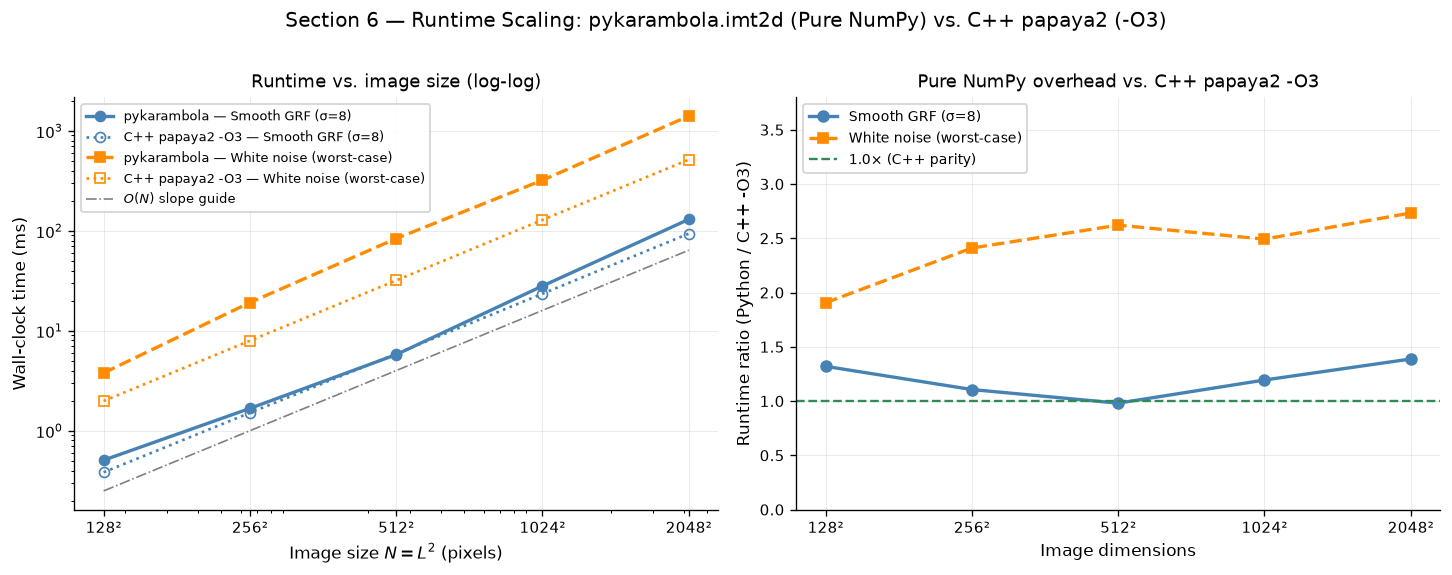

In [13]:
SIZES = [128, 256, 512, 1024, 2048]
rng_bench = np.random.default_rng(12345)

bench_rows = []
for L in SIZES:
    repeats = 5 if L <= 1024 else 3
    wn = rng_bench.standard_normal((L, L))
    grf = gaussian_filter(wn, sigma=8.0)

    for regime, img in [("Smooth GRF (σ=8)", grf), ("White noise (worst-case)", wn)]:
        # Warmup + best-of-repeats Python timing
        res_py = imt_image(img, threshold=0.0, boundary=0.0, xy_order=True)
        py_best_ms = float("inf")
        for _ in range(repeats):
            t0 = time.perf_counter()
            res_py = imt_image(img, threshold=0.0, boundary=0.0, xy_order=True)
            dt_ms = (time.perf_counter() - t0) * 1e3
            if dt_ms < py_best_ms:
                py_best_ms = dt_ms

        # Best-of-repeats C++ timing (compute only, excluding file I/O)
        cpp_best_ms, cpp_area, cpp_peri = cpp_bench(img, threshold=0.0, repeats=repeats)

        n_pix = L * L
        bench_rows.append({
            "Size": f"{L}×{L}",
            "L": L,
            "Pixels": n_pix,
            "Regime": regime,
            "C++ -O3 (ms)": cpp_best_ms,
            "Python NumPy (ms)": py_best_ms,
            "Ratio (Py / C++)": py_best_ms / cpp_best_ms,
            "Py Throughput (Mpx/s)": (n_pix / 1e6) / (py_best_ms / 1e3),
            "|Δarea|": abs(res_py["area"] - cpp_area),
        })

df_bench = pd.DataFrame(bench_rows)
display(
    df_bench[["Size", "Pixels", "Regime", "C++ -O3 (ms)", "Python NumPy (ms)", "Ratio (Py / C++)", "Py Throughput (Mpx/s)", "|Δarea|"]]
    .style.format({
        "Pixels": "{:,}",
        "C++ -O3 (ms)": "{:.2f}",
        "Python NumPy (ms)": "{:.2f}",
        "Ratio (Py / C++)": "{:.2f}×",
        "Py Throughput (Mpx/s)": "{:.1f}",
        "|Δarea|": "{:.2e}",
    })
)

# ── Log-log runtime scaling + Python/C++ ratio plot ──────────────────────────
fig, (ax_t, ax_r) = plt.subplots(1, 2, figsize=(12.2, 4.7))

style_map = {
    "Smooth GRF (σ=8)": ("steelblue", "o", "-"),
    "White noise (worst-case)": ("darkorange", "s", "--"),
}

for regime, (color, marker, ls) in style_map.items():
    sub = df_bench[df_bench["Regime"] == regime]
    ax_t.loglog(sub["Pixels"], sub["Python NumPy (ms)"], marker=marker, ls=ls, color=color, lw=2.0, ms=6, label=f"pykarambola — {regime}")
    ax_t.loglog(sub["Pixels"], sub["C++ -O3 (ms)"], marker=marker, ls=":", mfc="none", color=color, lw=1.6, ms=6, label=f"C++ papaya2 -O3 — {regime}")
    ax_r.plot(sub["L"], sub["Ratio (Py / C++)"], marker=marker, ls=ls, color=color, lw=2.0, ms=6.5, label=regime)

# O(N) linear-scaling guide line
n_ref = np.array([SIZES[0]**2, SIZES[-1]**2], dtype=np.float64)
ax_t.loglog(n_ref, 0.25 * (n_ref / n_ref[0]), color="0.5", ls="-.", lw=1.0, label=r"$O(N)$ slope guide")

ax_t.set_xlabel(r"Image size $N = L^2$ (pixels)")
ax_t.set_ylabel("Wall-clock time (ms)")
ax_t.set_title("Runtime vs. image size (log-log)")
ax_t.set_xticks([L**2 for L in SIZES])
ax_t.set_xticklabels([f"{L}²" for L in SIZES])
ax_t.legend(loc="upper left", fontsize=8, frameon=True, framealpha=0.88)

ax_r.axhline(1.0, color="seagreen", ls="--", lw=1.4, label="1.0× (C++ parity)")
ax_r.set_xscale("log", base=2)
ax_r.set_xticks(SIZES)
ax_r.set_xticklabels([f"{L}²" for L in SIZES])
ax_r.set_ylim(0, max(3.8, df_bench["Ratio (Py / C++)"].max() * 1.35))
ax_r.set_xlabel("Image dimensions")
ax_r.set_ylabel("Runtime ratio (Python / C++ -O3)")
ax_r.set_title("Pure NumPy overhead vs. C++ papaya2 -O3")
ax_r.legend(loc="upper left", fontsize=8.5, frameon=True, framealpha=0.88)

fig.suptitle("Section 6 — Runtime Scaling: pykarambola.imt2d (Pure NumPy) vs. C++ papaya2 (-O3)", fontsize=12.2, y=1.01)
plt.tight_layout()
plt.show()


---
## Conclusions

1. **Machine-precision agreement across every algorithm and flag:** Across all
   181 full IMT comparisons (analytic & random polygons, all 128 exhaustive
   16-case × 8-flag marching-squares runs at anisotropic spacing, 25-threshold
   `potato.png` excursion-set sweep, and 24 boundary/method/flag combinations on
   a 64×48 random grayscale image) plus 15 Minkowski maps (~46,000 complex
   cells), `pykarambola.imt2d` matches C++ `morphometry/papaya2` to near
   IEEE-754 float64 precision.
2. **Exact coordinate-convention bridge:** On `potato.png`, `xy_order=True`
   matches `papaya2` bit-accurately, while the default bioimage `(row, col)`
   convention (`xy_order=False`) preserves all scalars (`area`, `perimeter`,
   `beta102`, `isoper`) and rotation invariants ($q_s$) identically while taking
   the exact complex conjugate $\psi_s^{(\text{rc})} = \overline{\psi_s^{(\text{xy})}}$.
3. **Orientation robustness:** Interpolated marching squares reduces peak-to-peak
   orientation drift on a rotated 8:3 ellipse by ~300× compared to regular
   binarized marching squares, with $\lesssim 10^{-15}$ Python-vs-C++ residuals
   at every angle from $0^\circ$ to $90^\circ$.
4. **Near-C++ pure-NumPy performance:** On smooth Gaussian Random Fields up to
   $2048^2$ pixels (4.2M pixels), pure-NumPy `pykarambola.imt_image` runs within
   **~1.0–1.5×** of `g++ -O3` C++ `papaya2` (~30–44 Mpx/s), and within
   **~1.9–2.8×** on worst-case white noise, with zero compiled extensions required.
